# Phase 1 · Task 1.1 – 1.3 (UCI HAR)
스펙트럼 분석 → aliasing 재현 → EMA 필터 뱅크 분류. 용어 설명·해석·분석 검토는 [`README.md`](README.md) 참고.

- 공식 test는 로드하지 않는다. 공식 train 피험자를 **subject 단위**로 train/validation으로 나눠 사용한다.
- 스펙트럼 관습(모든 조건 동일): one-sided PSD, periodic Hann, 평균 제거, `scaling="density"`, **power(PSD) 평균**.

## 0. Setup & 데이터

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd() if (Path.cwd() / "mamba_starter").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "mamba_starter"))
from data import load_har, subject_split, HAR_CHANNELS, HAR_CLASSES
from signal_utils import power_spectrum, downsample, upsample, alias_frequency, ema, ema_features
from train import metrics

FS = 50.0                                    # UCI HAR sampling rate [Hz]
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.fontsize": 8})
ACT_COLORS = plt.cm.tab10(np.arange(6))
GROUPS = {"body_acc": [0, 1, 2], "body_gyro": [3, 4, 5], "total_acc": [6, 7, 8]}
GROUP_UNIT = {"body_acc": "g", "body_gyro": "rad/s", "total_acc": "g"}

In [2]:
x_all, y_all, subj_all = load_har(ROOT / "mamba_starter" / "data" / "har")   # 공식 TRAIN만: [7352,128,9]
tr, va = subject_split(subj_all, val_fraction=0.2, split_seed=42)             # train_ema.py 기본값과 동일
xtr, ytr, xva, yva = x_all[tr], y_all[tr], x_all[va], y_all[va]
assert not set(subj_all[tr]) & set(subj_all[va])                              # 피험자 겹침 없음

print("channels:", HAR_CHANNELS)
print("train subjects:", np.unique(subj_all[tr]).tolist())
print("val   subjects:", np.unique(subj_all[va]).tolist())
pd.DataFrame({"train": np.bincount(ytr, minlength=6), "val": np.bincount(yva, minlength=6)}, index=HAR_CLASSES)

channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']
train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 19, 22, 23, 27, 28, 29]
val   subjects: [17, 21, 25, 26, 30]


,train,val
WALKING,915,311
WALKING_UPSTAIRS,793,280
WALKING_DOWNSTAIRS,725,261
SITTING,932,354
STANDING,1000,374
LAYING,1027,380


## Task 1.1 · Spectral analysis
윈도우마다 `power_spectrum` → one-sided PSD `[N, 65, 9]` → 활동별 윈도우 평균(power). 0 Hz bin은 평균 제거로 비어 있어 그림·표에서 제외.

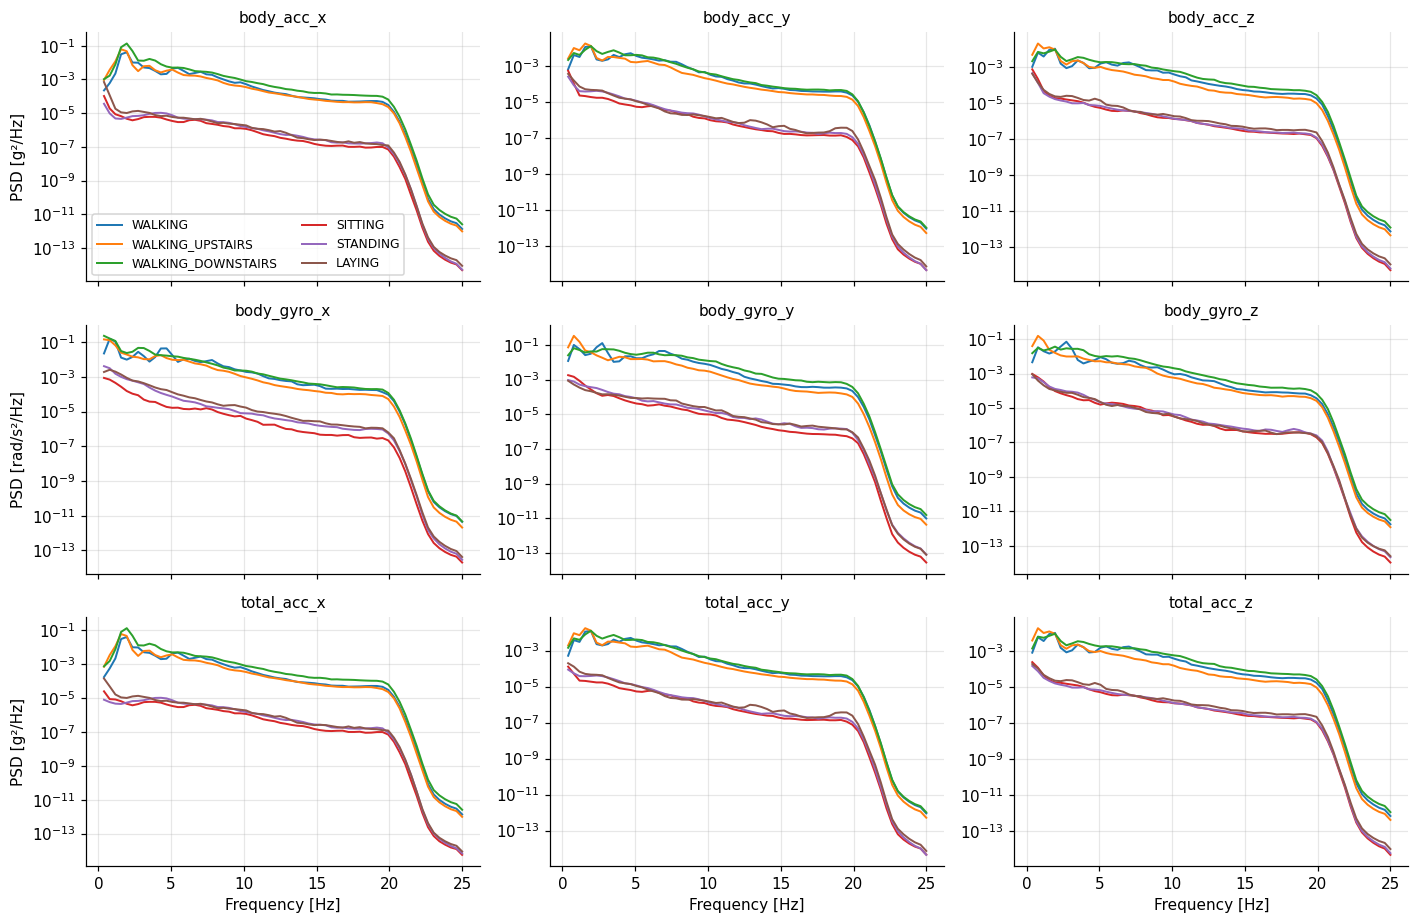

In [3]:
f, P = power_spectrum(xtr, FS)               # f: 0 … 25 Hz (Δf = 0.390625), P: [N, 65, 9]
Pc = np.stack([P[ytr == k].mean(0) for k in range(6)])        # class-mean PSD [6, 65, 9]
df = f[1] - f[0]

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True)      # 채널별 (평균 전에 먼저 확인)
for g, (name, idx) in enumerate(GROUPS.items()):
    for j, c in enumerate(idx):
        ax = axes[g, j]
        for k in range(6):
            ax.semilogy(f[1:], Pc[k, 1:, c], color=ACT_COLORS[k], label=HAR_CLASSES[k], lw=1.3)
        ax.set_title(HAR_CHANNELS[c], fontsize=10)
        if j == 0: ax.set_ylabel(f"PSD [{GROUP_UNIT[name]}²/Hz]")
        if g == 2: ax.set_xlabel("Frequency [Hz]")
axes[0, 0].legend(ncol=2)
fig.tight_layout(); fig.savefig(FIG / "t1_1_per_channel.png", bbox_inches="tight"); plt.show()

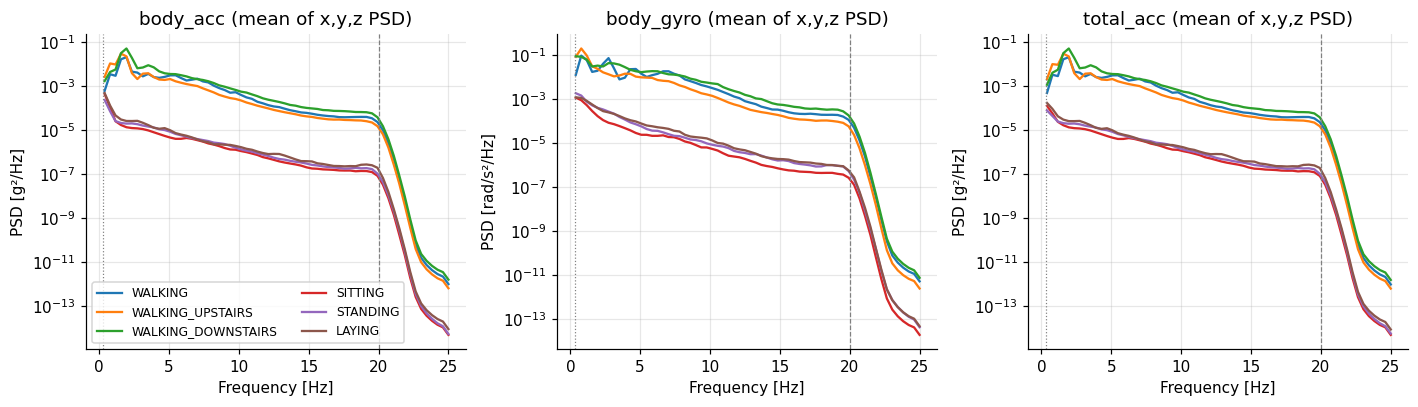

In [4]:
Pg = {name: Pc[:, :, idx].mean(-1) for name, idx in GROUPS.items()}      # 센서 그룹 내 x,y,z 평균 [6, 65]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, (name, v) in zip(axes, Pg.items()):
    for k in range(6):
        ax.semilogy(f[1:], v[k, 1:], color=ACT_COLORS[k], label=HAR_CLASSES[k], lw=1.5)
    ax.set(title=f"{name} (mean of x,y,z PSD)", xlabel="Frequency [Hz]", ylabel=f"PSD [{GROUP_UNIT[name]}²/Hz]")
    ax.axvline(0.3, color="gray", ls=":", lw=.8); ax.axvline(20, color="gray", ls="--", lw=.8)   # 0.3 Hz / 20 Hz (제작자 필터)
axes[0].legend(ncol=2)
fig.tight_layout(); fig.savefig(FIG / "t1_1_per_group.png", bbox_inches="tight"); plt.show()

In [5]:
BANDS = [(0.0, 0.5), (0.5, 3.0), (3.0, 10.0), (10.0, 25.01)]
rows = []
for name, v in Pg.items():
    for k in range(6):
        tot = v[k, 1:].sum()
        fr = [v[k][(f >= lo) & (f < hi) & (f > 0)].sum() / tot for lo, hi in BANDS]       # 0 Hz 제외 전력 비율
        rows.append({"group": name, "activity": HAR_CLASSES[k], "peak_Hz": f[1:][v[k, 1:].argmax()],
                     **{f"{lo:g}-{min(hi,25):g}Hz": fr[i] for i, (lo, hi) in enumerate(BANDS)}})
band_table = pd.DataFrame(rows)
RESULTS["task1_1_band_table"] = band_table.round(4).to_dict("records")
band_table.style.format({"peak_Hz": "{:.2f}", **{c: "{:.1%}" for c in band_table.columns[3:]}}).background_gradient(
    subset=list(band_table.columns[3:]), cmap="Blues", axis=None)

,group,activity,peak_Hz,0-0.5Hz,0.5-3Hz,3-10Hz,10-25Hz
0,body_acc,WALKING,1.95,0.7%,57.9%,38.6%,2.9%
1,body_acc,WALKING_UPSTAIRS,1.56,2.4%,72.4%,23.7%,1.5%
2,body_acc,WALKING_DOWNSTAIRS,1.95,0.9%,65.3%,31.4%,2.4%
3,body_acc,SITTING,0.39,61.7%,26.1%,11.0%,1.2%
4,body_acc,STANDING,0.39,43.7%,32.7%,21.5%,2.1%
5,body_acc,LAYING,0.39,53.0%,31.3%,14.1%,1.6%
6,body_gyro,WALKING,0.78,2.2%,53.9%,40.7%,3.2%
7,body_gyro,WALKING_UPSTAIRS,0.78,13.8%,63.0%,21.9%,1.4%
8,body_gyro,WALKING_DOWNSTAIRS,0.39,12.4%,39.6%,43.5%,4.6%
9,body_gyro,SITTING,0.39,31.4%,55.5%,12.2%,0.9%


## Task 1.2 · Reproducing aliasing
50 Hz → 25 / 12.5 / 6.25 Hz (M = 2 / 4 / 8; 새 Nyquist 12.5 / 6.25 / 3.125 Hz), (a) naive `x[::M]`, (b) anti-aliased(zero-phase FIR low-pass 후 decimation).
윈도우 지속시간(2.56 s)이 같아 Δf는 모두 0.39 Hz → 같은 bin 격자에서 직접 비교.

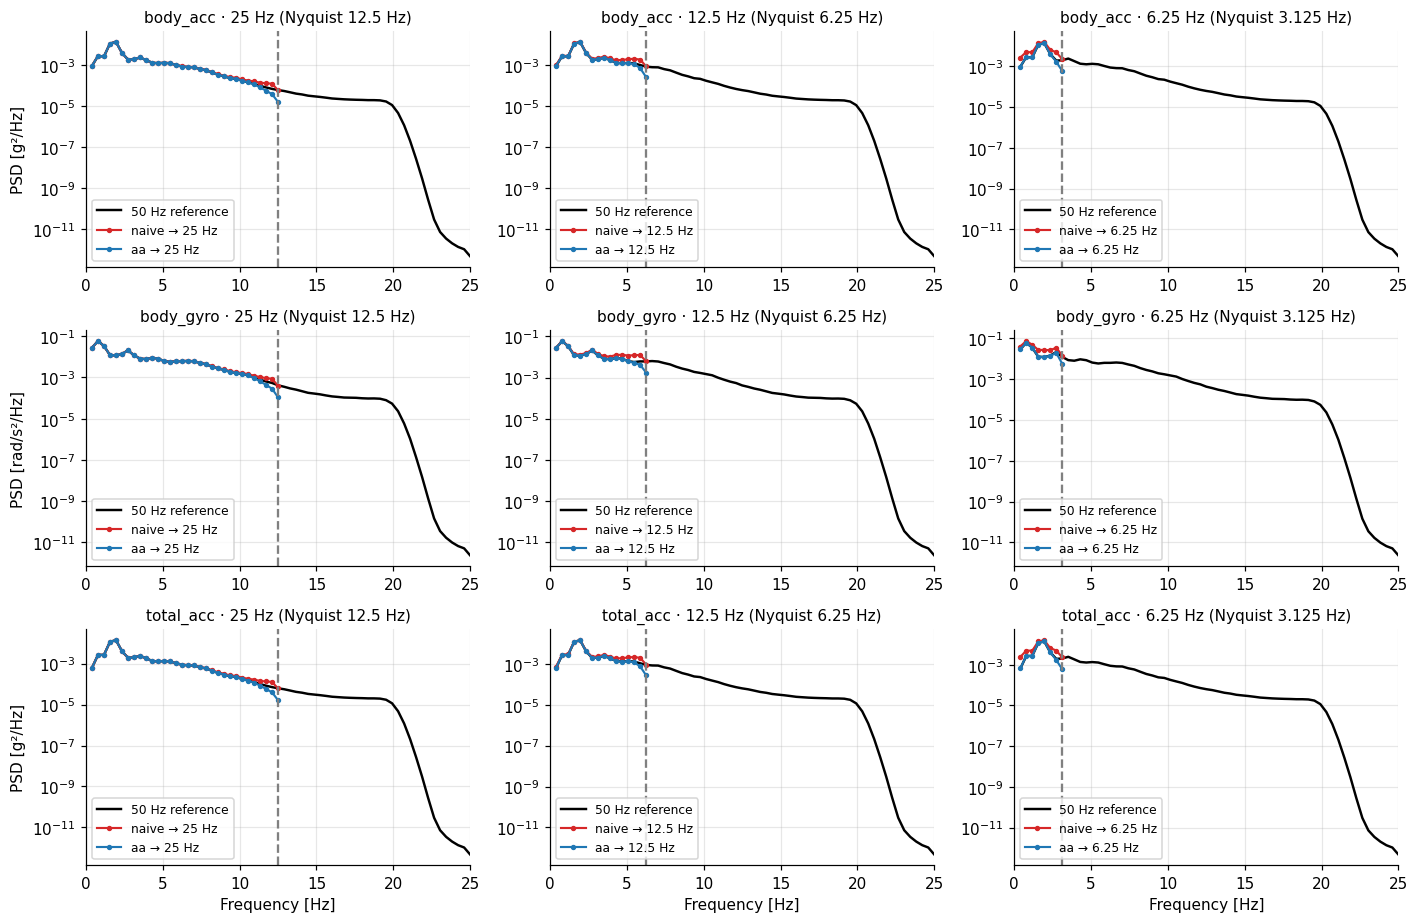

In [6]:
RATES = {2: 25.0, 4: 12.5, 8: 6.25}
spec = {"ref": P.mean(0)}                                    # 전체 train 윈도우 평균 PSD [65, 9]
for M, fs_new in RATES.items():
    for meth in ("naive", "aa"):
        ff, pp = power_spectrum(downsample(xtr, M, meth), fs_new)
        spec[(M, meth)] = (ff, pp.mean(0))

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5))
for g, (name, idx) in enumerate(GROUPS.items()):
    for j, (M, fs_new) in enumerate(RATES.items()):
        ax = axes[g, j]
        ax.semilogy(f[1:], spec["ref"][1:, idx].mean(-1), "k", lw=1.6, label="50 Hz reference")
        for meth, col in (("naive", "tab:red"), ("aa", "tab:blue")):
            ff, pp = spec[(M, meth)]
            ax.semilogy(ff[1:], pp[1:, idx].mean(-1), color=col, lw=1.4, marker="o", ms=2.5, label=f"{meth} → {fs_new:g} Hz")
        ax.axvline(fs_new / 2, color="gray", ls="--"); ax.set_xlim(0, 25)
        ax.set_title(f"{name} · {fs_new:g} Hz (Nyquist {fs_new/2:g} Hz)", fontsize=10)
        if j == 0: ax.set_ylabel(f"PSD [{GROUP_UNIT[name]}²/Hz]")
        if g == 2: ax.set_xlabel("Frequency [Hz]")
        ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "t1_2_naive_vs_aa.png", bbox_inches="tight"); plt.show()

In [7]:
# above_Nyquist: 50 Hz 스펙트럼에서 새 Nyquist 위에 있던 전력 비율 (aliasing으로 접힐 수 있는 양)
# inband_change: 새 Nyquist 이하 전력이 50 Hz 기준 대비 얼마나 변했나
rows = []
for name, idx in GROUPS.items():
    ref = spec["ref"][:, idx].mean(-1)
    for M, fs_new in RATES.items():
        nb = len(spec[(M, "naive")][0])                      # bins 0 … fs_new/2
        row = {"group": name, "rate_Hz": fs_new, "above_Nyquist": ref[nb:].sum() / ref[1:].sum()}
        for meth in ("naive", "aa"):
            row[f"inband_change_{meth}"] = spec[(M, meth)][1][1:, idx].mean(-1).sum() / ref[1:nb].sum() - 1
        rows.append(row)
alias_table = pd.DataFrame(rows)
RESULTS["task1_2_alias_table"] = alias_table.round(5).to_dict("records")
alias_table.style.format({c: "{:.2%}" for c in alias_table.columns[2:]})

,group,rate_Hz,above_Nyquist,inband_change_naive,inband_change_aa
0,body_acc,25.000000,0.92%,0.88%,-0.11%
1,body_acc,12.500000,9.98%,11.01%,-1.80%
2,body_acc,6.250000,29.85%,39.57%,-3.94%
3,body_gyro,25.000000,0.98%,0.99%,-0.22%
4,body_gyro,12.500000,14.72%,17.49%,-2.62%
5,body_gyro,6.250000,34.49%,47.95%,-4.38%
6,total_acc,25.000000,0.93%,0.89%,-0.12%
7,total_acc,12.500000,10.11%,11.15%,-1.84%
8,total_acc,6.250000,30.22%,40.24%,-4.04%


## Task 1.2b · Making aliasing visible
18 Hz tone의 alias를 실행 전에 예측: 25 Hz → 7.0, 12.5 Hz → 5.5, 6.25 Hz → 0.75 Hz (`alias_frequency`). 그 뒤 순수 tone과 HAR+tone으로 검증하고, naive로 줄인 신호를 50 Hz로 보간해 복원 여부를 본다.

In [8]:
F_TONE = 18.0
pred = {M: alias_frequency(F_TONE, fs_new) for M, fs_new in RATES.items()}
print("predicted alias [Hz]:", pred)

rng = np.random.default_rng(0)
t = np.arange(128) / FS
tone = np.sin(2 * np.pi * F_TONE * t[None, :, None] + rng.uniform(0, 2 * np.pi, (len(xtr), 1, 1)))   # [N,128,1]

def psd_mean(xx, fs_):
    ff, pp = power_spectrum(xx, fs_)
    return ff, pp.mean((0, 2))

ff0, m0 = psd_mean(tone, FS); i0 = m0[1:].argmax() + 1
rows = [{"rate_Hz": 50.0, "method": "reference", "predicted_alias_Hz": F_TONE, "measured_peak_Hz": ff0[i0], "PSD@predicted_alias_dB": 0.0}]
for M, fs_new in RATES.items():
    for meth in ("naive", "aa"):
        ff, m = psd_mean(downsample(tone, M, meth), fs_new)
        ia = np.abs(ff - pred[M]).argmin()                    # 예측 alias에 가장 가까운 bin
        rows.append({"rate_Hz": fs_new, "method": meth, "predicted_alias_Hz": pred[M],
                     "measured_peak_Hz": ff[m[1:].argmax() + 1] if meth == "naive" else np.nan,
                     "PSD@predicted_alias_dB": 10 * np.log10(m[ia] / m0[i0])})      # 원래 tone peak 대비 dB
tone_table = pd.DataFrame(rows)
tone_table["abs_err_Hz"] = (tone_table.measured_peak_Hz - tone_table.predicted_alias_Hz).abs()
RESULTS["task1_2b_tone_table"] = tone_table.round(4).to_dict("records")
tone_table.round(3)

predicted alias [Hz]: {2: 7.0, 4: 5.5, 8: 0.75}


,rate_Hz,method,predicted_alias_Hz,measured_peak_Hz,PSD@predicted_alias_dB,abs_err_Hz
0,50.00,reference,18.00,17.969,0.000,0.031
1,25.00,naive,7.00,7.031,0.000,0.031
2,25.00,aa,7.00,NaN,-62.729,NaN
3,12.50,naive,5.50,5.469,-0.000,0.031
4,12.50,aa,5.50,NaN,-57.127,NaN
5,6.25,naive,0.75,0.781,-0.000,0.031
6,6.25,aa,0.75,NaN,-69.734,NaN


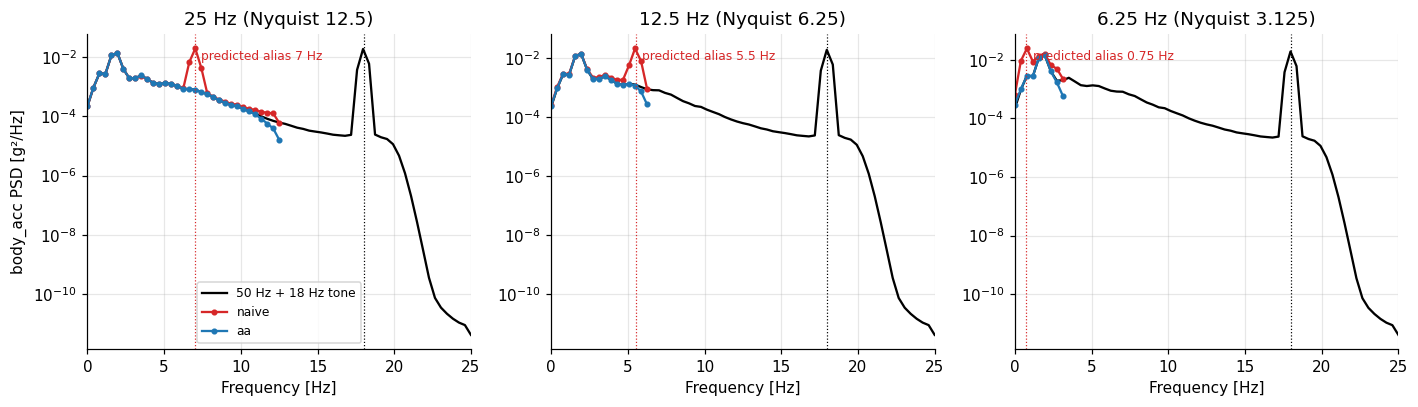

In [9]:
x_tone = xtr + tone * xtr.std((0, 1), keepdims=True)         # 실제 HAR 윈도우 + 채널 표준편차 크기의 18 Hz tone
body = GROUPS["body_acc"]
ref_t = power_spectrum(x_tone, FS)[1].mean(0)[:, body].mean(-1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (M, fs_new) in zip(axes, RATES.items()):
    ax.semilogy(f, ref_t, "k", lw=1.5, label="50 Hz + 18 Hz tone")
    for meth, col in (("naive", "tab:red"), ("aa", "tab:blue")):
        ff, pp = power_spectrum(downsample(x_tone, M, meth), fs_new)
        ax.semilogy(ff, pp.mean(0)[:, body].mean(-1), color=col, marker="o", ms=3, label=meth)
    ax.axvline(F_TONE, color="k", ls=":", lw=.8); ax.axvline(pred[M], color="tab:red", ls=":", lw=.8)
    ax.text(pred[M] + .4, .95, f"predicted alias {pred[M]:g} Hz", transform=ax.get_xaxis_transform(), color="tab:red", fontsize=8, va="top")
    ax.set(title=f"{fs_new:g} Hz (Nyquist {fs_new/2:g})", xlabel="Frequency [Hz]", xlim=(0, 25))
axes[0].set_ylabel("body_acc PSD [g²/Hz]"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "t1_2b_tone_on_har.png", bbox_inches="tight"); plt.show()

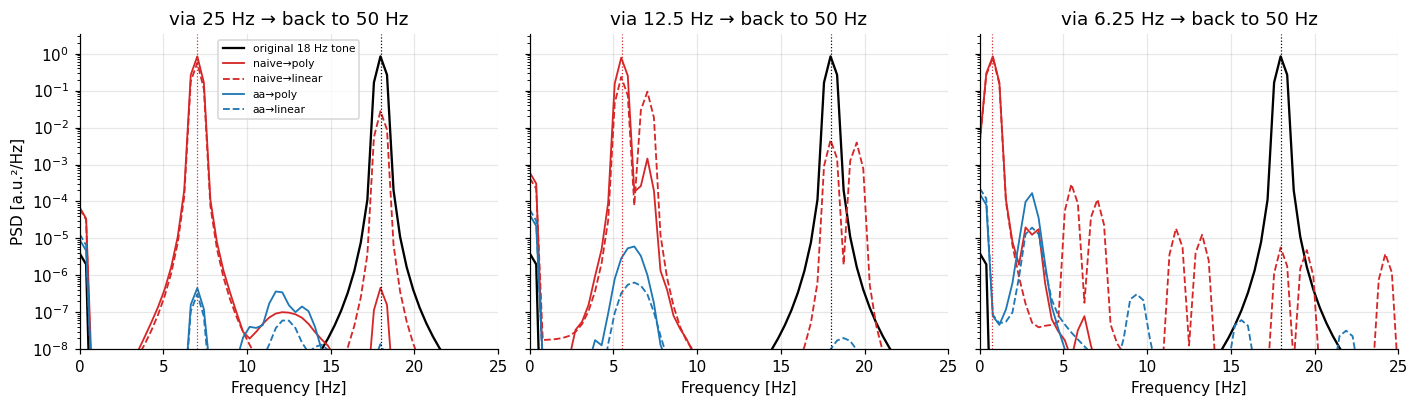

,rate_Hz,down,up,alias_Hz,power@18Hz / original,power@alias / original@18Hz
0,25.00,naive,poly,7.00,0.0000,0.9995
1,25.00,naive,linear,7.00,0.0329,0.6703
2,25.00,aa,poly,7.00,0.0000,0.0000
3,25.00,aa,linear,7.00,0.0000,0.0000
4,12.50,naive,poly,5.50,0.0000,0.9271
5,12.50,naive,linear,5.50,0.0054,0.2762
6,12.50,aa,poly,5.50,0.0000,0.0000
7,12.50,aa,linear,5.50,0.0000,0.0000
8,6.25,naive,poly,0.75,0.0000,1.0243
9,6.25,naive,linear,0.75,0.0000,0.9323


In [10]:
def band_power(xx, lo, hi):
    ff, pp = power_spectrum(xx, FS)
    m = pp.mean((0, 2)); sel = (ff >= lo) & (ff <= hi)
    return m[sel].sum() * (ff[1] - ff[0])

p18 = band_power(tone, F_TONE - .4, F_TONE + .4)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
rows = []
for ax, (M, fs_new) in zip(axes, RATES.items()):
    ax.semilogy(f, power_spectrum(tone, FS)[1].mean((0, 2)), "k", lw=1.5, label="original 18 Hz tone")
    for meth, col in (("naive", "tab:red"), ("aa", "tab:blue")):
        for interp, ls in (("poly", "-"), ("linear", "--")):
            rec = upsample(downsample(tone, M, meth), M, interp)          # 줄였다가 50 Hz로 되돌림
            ax.semilogy(f, power_spectrum(rec, FS)[1].mean((0, 2)), color=col, ls=ls, lw=1.2, label=f"{meth}→{interp}")
            rows.append({"rate_Hz": fs_new, "down": meth, "up": interp, "alias_Hz": pred[M],
                         "power@18Hz / original": band_power(rec, F_TONE - .4, F_TONE + .4) / p18,
                         "power@alias / original@18Hz": band_power(rec, pred[M] - .4, pred[M] + .4) / p18})
    ax.axvline(F_TONE, color="k", ls=":", lw=.8); ax.axvline(pred[M], color="tab:red", ls=":", lw=.8)
    ax.set(title=f"via {fs_new:g} Hz → back to 50 Hz", xlabel="Frequency [Hz]", xlim=(0, 25), ylim=(1e-8, None))
axes[0].set_ylabel("PSD [a.u.²/Hz]"); axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "t1_2b_upsample.png", bbox_inches="tight"); plt.show()
rec_table = pd.DataFrame(rows)
RESULTS["task1_2b_upsample_table"] = [{k: float(v) if not isinstance(v, str) else v for k, v in r.items()} for r in rows]
rec_table.round(4)

## Task 1.3 · EMA as a hand-made SSM
`h[t] = a·h[t-1] + (1−a)·x[t]` (초기 상태 0). Mamba의 `a_t = exp(Δ_t·A)`와 대응 → `Δ = ln(a)/A`.

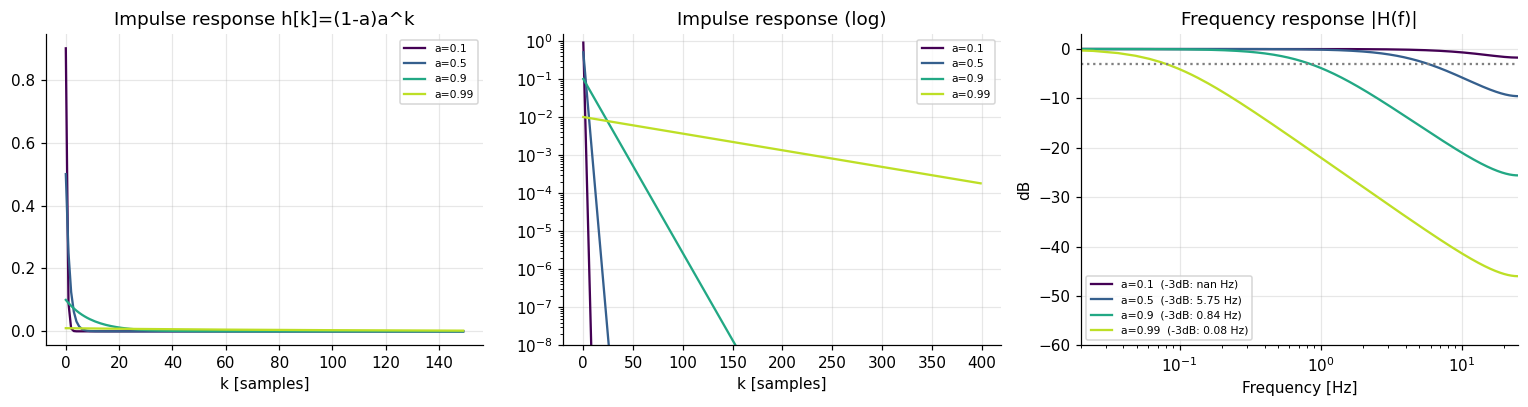

In [11]:
ALPHAS = [0.1, 0.5, 0.9, 0.99]                       # 사전에 고정한 선택 (half-life ≈ 0.3, 1, 6.6, 69 samples)
L = 400
delta = np.zeros((L, 1)); delta[0] = 1
impulse = {a: ema(delta[None], a)[0, :, 0] for a in ALPHAS}
for a in ALPHAS:                                      # starter 구현 == 해석식 (1-a)a^k
    assert np.allclose(impulse[a], (1 - a) * a ** np.arange(L)), a

def cutoff_hz(a):                                     # |H|² = 1/2 → cosω = (-a²+4a-1)/(2a), a ≥ 2-√3 에서만 존재
    if a < 2 - np.sqrt(3): return np.nan
    return np.arccos((-a**2 + 4*a - 1) / (2*a)) / (2*np.pi) * FS

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
cols = plt.cm.viridis(np.linspace(0, .9, len(ALPHAS)))
for a, c in zip(ALPHAS, cols):
    axes[0].plot(np.arange(150), impulse[a][:150], color=c, label=f"a={a}")
    axes[1].semilogy(np.arange(L), impulse[a], color=c, label=f"a={a}")
    w, H = signal.freqz([1 - a], [1, -a], worN=2048, fs=FS)
    axes[2].plot(w, 20 * np.log10(np.abs(H)), color=c, label=f"a={a}  (-3dB: {cutoff_hz(a):.2f} Hz)")
axes[0].set(title="Impulse response h[k]=(1-a)a^k", xlabel="k [samples]")
axes[1].set(title="Impulse response (log)", xlabel="k [samples]", ylim=(1e-8, 1.5))
axes[2].set(title="Frequency response |H(f)|", xlabel="Frequency [Hz]", ylabel="dB", xscale="log", xlim=(0.02, 25), ylim=(-60, 3))
axes[2].axhline(-3, color="gray", ls=":")
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "t1_3_ema_responses.png", bbox_inches="tight"); plt.show()

In [12]:
rows = [{"a": a, "Δ·|A| = -ln a": -np.log(a), "Δ (A=-1)": -np.log(a), "input gain 1-a": 1 - a,
         "time const τ [samples]": -1 / np.log(a), "half-life [samples]": np.log(2) / -np.log(a),
         "half-life [s @50Hz]": np.log(2) / -np.log(a) / FS, "-3dB cutoff [Hz]": cutoff_hz(a),
         "gain @Nyquist (1-a)/(1+a)": (1 - a) / (1 + a)} for a in ALPHAS]
ema_table = pd.DataFrame(rows)
RESULTS["task1_3_a_delta_table"] = ema_table.round(5).to_dict("records")
display(ema_table.round(4))

# 같은 a를 만드는 (Δ, A)는 많다 → 기억은 Δ 단독이 아니라 Δ·A 로 결정 (Mamba 초기화: Δ∈[0.001,0.1], |A|∈{1..16})
pd.DataFrame({f"|A|={A}": [np.exp(-d * A) for d in (0.001, 0.01, 0.1)] for A in (1, 4, 16)},
             index=[f"Δ={d}" for d in (0.001, 0.01, 0.1)]).round(4)

,a,Δ·|A| = -ln a,Δ (A=-1),input gain 1-a,time const τ [samples],half-life [samples],half-life [s @50Hz],-3dB cutoff [Hz],gain @Nyquist (1-a)/(1+a)
0,0.10,2.3026,2.3026,0.90,0.4343,0.3010,0.0060,NaN,0.8182
1,0.50,0.6931,0.6931,0.50,1.4427,1.0000,0.0200,5.7513,0.3333
2,0.90,0.1054,0.1054,0.10,9.4912,6.5788,0.1316,0.8392,0.0526
3,0.99,0.0101,0.0101,0.01,99.4992,68.9676,1.3794,0.0800,0.0050


,|A|=1,|A|=4,|A|=16
Δ=0.001,0.9990,0.9960,0.9841
Δ=0.01,0.9900,0.9608,0.8521
Δ=0.1,0.9048,0.6703,0.2019


In [13]:
GRID = [0.0, 0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.97, 0.99, 0.995]

def fit_eval(alphas, tr_idx=tr, va_idx=va, feat=ema_features):
    # 채널별 EMA → mean/std/RMS → StandardScaler(train fit) → LogisticRegression (= train_ema.py)
    ftr, fva = feat(x_all[tr_idx], alphas), feat(x_all[va_idx], alphas)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=0)).fit(ftr, y_all[tr_idx])
    m = metrics(y_all[va_idx], pipe.predict(fva), 6); m["feature_dim"] = ftr.shape[1]
    return m

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sweep = {a: fit_eval([a]) for a in GRID}              # 단일 a (a=0: 필터 없는 raw mean/std/RMS)
    final = fit_eval(ALPHAS)
sweep_df = pd.DataFrame({"a": GRID, "half-life [samples]": [np.log(2) / -np.log(a) if a > 0 else 0 for a in GRID],
                         "val_acc": [sweep[a]["accuracy"] for a in GRID], "val_macro_F1": [sweep[a]["macro_f1"] for a in GRID]})
print(f"FINAL  alphas={ALPHAS}  dim={final['feature_dim']}  val acc={final['accuracy']:.4f}  macro-F1={final['macro_f1']:.4f}")
RESULTS["task1_3"] = {"alphas": ALPHAS, "accuracy": final["accuracy"], "macro_f1": final["macro_f1"],
                      "confusion_matrix": final["confusion_matrix"], "single_alpha_sweep": sweep_df.round(5).to_dict("records")}
sweep_df.round(4)

FINAL  alphas=[0.1, 0.5, 0.9, 0.99]  dim=108  val acc=0.8990  macro-F1=0.8959


,a,half-life [samples],val_acc,val_macro_F1
0,0.000,0.0000,0.7745,0.7579
1,0.100,0.3010,0.7740,0.7573
2,0.300,0.5757,0.7730,0.7559
3,0.500,1.0000,0.7745,0.7577
4,0.700,1.9434,0.7893,0.7747
5,0.800,3.1063,0.8112,0.7996
6,0.900,6.5788,0.8577,0.8503
7,0.950,13.5134,0.8791,0.8753
8,0.970,22.7566,0.8796,0.8760
9,0.990,68.9676,0.8755,0.8708


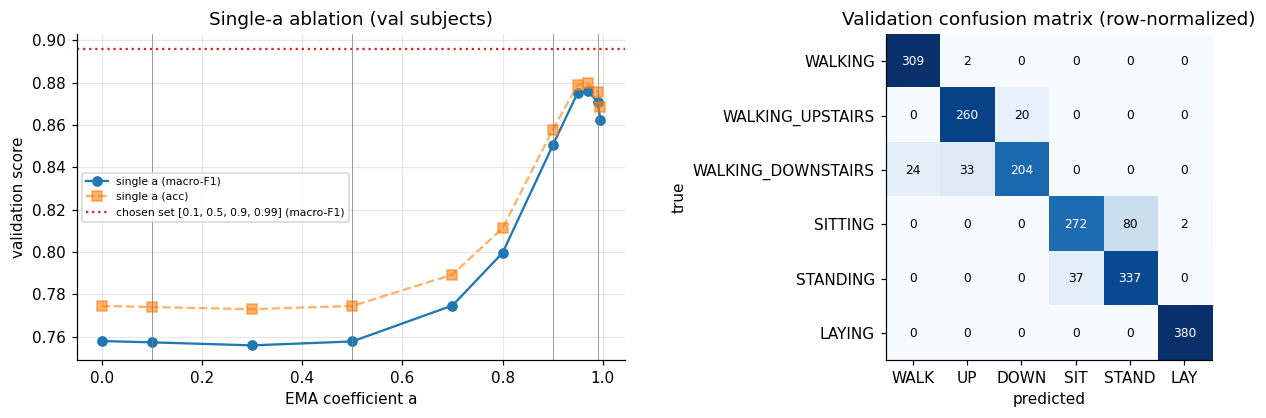

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].plot(sweep_df["a"], sweep_df["val_macro_F1"], "o-", label="single a (macro-F1)")
axes[0].plot(sweep_df["a"], sweep_df["val_acc"], "s--", alpha=.6, label="single a (acc)")
axes[0].axhline(final["macro_f1"], color="tab:red", ls=":", label=f"chosen set {ALPHAS} (macro-F1)")
for a in ALPHAS: axes[0].axvline(a, color="gray", lw=.5)
axes[0].set(xlabel="EMA coefficient a", ylabel="validation score", title="Single-a ablation (val subjects)"); axes[0].legend(fontsize=7)
cm = np.array(final["confusion_matrix"]); cmn = cm / cm.sum(1, keepdims=True)
axes[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
axes[1].set(xticks=range(6), yticks=range(6), title="Validation confusion matrix (row-normalized)", xlabel="predicted", ylabel="true")
axes[1].set_xticklabels(["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"]); axes[1].set_yticklabels(HAR_CLASSES); axes[1].grid(False)
for i in range(6):
    for j in range(6): axes[1].text(j, i, f"{cm[i,j]}", ha="center", va="center", color="w" if cmn[i, j] > .5 else "k", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "t1_3_ema_classifier.png", bbox_inches="tight"); plt.show()

## Sanity checks (분석이 맞게 돌았는지 확인)
(A) PSD 구현 단위·크기 확인 (B) 1.3 결론이 validation 분할에 의존하는지 (C) EMA 초기 상태(0 vs 첫 샘플) 영향 (D) 평균 제거가 지운 DC(중력) 정보.

In [15]:
# (A) 알려진 신호로 power_spectrum 검증: 백색잡음 σ²=1 → one-sided PSD = 2σ²/fs, 진폭 1 사인 → ∫PSD df = A²/2
noise = np.random.default_rng(1).normal(0, 1, (4000, 128, 1))
_, Pn = power_spectrum(noise, FS)
sine = np.sin(2 * np.pi * (13 * FS / 128) * t[None, :, None] + rng.uniform(0, 2 * np.pi, (500, 1, 1)))
_, Ps = power_spectrum(sine, FS)
chk_a = {"noise_PSD_measured": float(Pn.mean(0)[1:-1].mean()), "noise_PSD_expected": 2 / FS,
         "sine_power_measured": float(Ps.mean((0, 2)).sum() * df), "sine_power_expected": 0.5}
RESULTS["sanity_A"] = chk_a; chk_a

{'noise_PSD_measured': 0.03972030521999371,
 'noise_PSD_expected': 0.04,
 'sine_power_measured': 0.5000000000000034,
 'sine_power_expected': 0.5}

In [16]:
# (B) 5가지 다른 subject 분할(split_seed)에서 1.3 결론 재확인 — 모두 공식 train 피험자 안에서만 분할
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for ss in (42, 0, 1, 2, 3):
        t_i, v_i = subject_split(subj_all, 0.2, ss)
        rows.append({"split_seed": ss, "val_subjects": np.unique(subj_all[v_i]).tolist(),
                     "a=0 (raw)": fit_eval([0.0], t_i, v_i)["macro_f1"], "a=0.95": fit_eval([0.95], t_i, v_i)["macro_f1"],
                     "chosen set": fit_eval(ALPHAS, t_i, v_i)["macro_f1"]})
split_df = pd.DataFrame(rows)
RESULTS["sanity_B"] = split_df.round(4).to_dict("records")
print("mean±std macro-F1 over splits:\n", split_df[["a=0 (raw)", "a=0.95", "chosen set"]].agg(["mean", "std"]).round(4).to_string())
split_df.round(4)

mean±std macro-F1 over splits:
       a=0 (raw)  a=0.95  chosen set
mean     0.8219  0.8798      0.9042
std      0.0539  0.0152      0.0136


,split_seed,val_subjects,a=0 (raw),a=0.95,chosen set
0,42,"[17, 21, 25, 26, 30]",0.7579,0.8753,0.8959
1,0,"[5, 7, 17, 26, 28]",0.8653,0.8693,0.9082
2,1,"[3, 14, 19, 25, 30]",0.7824,0.8628,0.8852
3,2,"[19, 21, 23, 26, 29]",0.8180,0.8949,0.9188
4,3,"[6, 15, 16, 26, 27]",0.8859,0.8965,0.9130


In [17]:
# (C) EMA 초기 상태: starter는 h[-1]=0. 대안: h[-1]=x[0] (정상상태에서 시작). EMA는 선형·DC gain 1이므로 y = x0 + ema(x - x0)
def ema_features_warm(x, alphas):
    x0 = x[:, :1, :]
    out = []
    for a in alphas:
        y = ema(x - x0, a) + x0
        out += [y.mean(1), y.std(1), np.sqrt(np.mean(y * y, axis=1))]
    return np.concatenate(out, axis=1)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    warm = fit_eval(ALPHAS, feat=ema_features_warm)
RESULTS["sanity_C"] = {"zero_init_macro_f1": final["macro_f1"], "warm_init_macro_f1": warm["macro_f1"],
                       "zero_init_acc": final["accuracy"], "warm_init_acc": warm["accuracy"]}
RESULTS["sanity_C"]

{'zero_init_macro_f1': 0.8958643974014316,
 'warm_init_macro_f1': 0.8748385183402267,
 'zero_init_acc': 0.8989795918367347,
 'warm_init_acc': 0.8806122448979592}

In [18]:
# (D) 평균 제거가 지운 정보: 윈도우 평균(DC)=중력 방향. 클래스별 total_acc x,y,z 윈도우 평균의 mean/std
dc = xtr[:, :, 6:9].mean(1)
dc_df = pd.DataFrame({HAR_CLASSES[k]: np.r_[dc[ytr == k].mean(0), dc[ytr == k].std(0)] for k in range(6)},
                     index=["x_mean", "y_mean", "z_mean", "x_std", "y_std", "z_std"]).T
RESULTS["sanity_D"] = dc_df.round(4).to_dict("index")
dc_df.round(3)

,x_mean,y_mean,z_mean,x_std,y_std,z_std
WALKING,0.995,-0.186,-0.088,0.031,0.075,0.151
WALKING_UPSTAIRS,0.943,-0.279,-0.177,0.051,0.103,0.201
WALKING_DOWNSTAIRS,0.990,-0.155,-0.084,0.033,0.082,0.148
SITTING,0.950,0.147,0.169,0.103,0.184,0.208
STANDING,1.005,-0.152,-0.031,0.021,0.097,0.148
LAYING,0.068,0.632,0.525,0.137,0.346,0.438


In [19]:
(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "phase1_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))

16819